I ('T_dim', 'X_dim', 'Color_dim') (1200, 1181, 3)
    8-bit image color values of the timestack. Three dimensions: time, spatial axis, color band, where the colors are RGB (R=0, G=1, B=2). The horizontal axis of the image is the spatial axis. The different crs mappings represent the same coordinates in UTM, local, and longitude/latitude.
crs_utm () ()
    Coordinate reference system definition for UTM coordinates.
crs_latlon () ()
    Coordinate reference system definition for longitude/latitude coordinates.
Ri ('T_dim',) (1200,)
    Pixel coordinate of wave runup line as found by the SegFormer model.
runup_val () ()
    Runup value used to extract runup from softmax score.
rundown_val () ()
    Rundown value used to extract rundown from softmax score.
U_transect ('X_dim',) (1181,)
    Pixel coordinate along the horizontal axis of the image where the timestack was sampled.
V_transect ('X_dim',) (1181,)
    Pixel coordinate along the vertical axis of the image where the timestack was sampled.
T ('T_dim',) (1200,)
    Times that pixels were sampled to create the timestack. Format: YYYY-MM-DD HH:mm:SS+00:00. The dimension length equals the number of samples in the timestack.
eastings_transect ('X_dim',) (1181,)
    Easting coordinates of timestack pixels projected onto the beach surface, described in UTM Easting meters.
northings_transect ('X_dim',) (1181,)
    Northing coordinates of timestack pixels projected onto the beach surface, described in UTM Northing meters.
elevation_transect ('X_dim',) (1181,)
    Elevation (z-value) of timestack pixels projected onto the beach surface.
localX_transect ('X_dim',) (1181,)
    Local cross-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin.
localY_transect ('X_dim',) (1181,)
    Local along-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin
Hrunup_utm ('T_dim', 'XY_dim') (1200, 2)
    Horizontal coordinates of wave runup converted from image coordinates (U,V) to Eastings and Northings.
Hrunup_local ('T_dim', 'XY_dim') (1200, 2)
    Horizontal coordinates of wave runup in the local coordinate system. Rotated based on shore-normal angle and origin.
TWL ('T_dim',) (1200,)
    Vertical elevation of total water level.
Zrunup ('T_dim',) (1200,)
    Vertical elevation of wave runup (total water level minus TWL_tideWindSetup).
TWLstats_2exceedence_peaks () ()
    2 percent exceedance value for TWL peaks.
TWLstats_2exceedence_notpeaks () ()
    2 percent exceedance value for the full TWL time series.
TWLstats_setup () ()
    Wave setup.
TWLstats_Tpeak () ()
    Runup (or TWL) time series peak period.
TWLstats_Tmean () ()
    Runup (or TWL) time series mean period.
TWLstats_Ssig () ()
    Significant swash.
TWLstats_Ssig_SS () ()
    Significant swash in the sea-swell band.
TWLstats_Ssig_IG () ()
    Significant swash in the infragravity band.
TWLstats_spectrum ('TWLstats_dim',) (151,)
    Runup (or TWL) spectral density array.
TWLstats_frequency ('TWLstats_dim',) (151,)
    Runup (or TWL) frequency array.
TWLstats_betaS2006 () ()
    Beach slope between ±2 standard deviations of the TWL time series, as defined in Stockdon et al. (2006).
TWLstats_beta () ()
    Beach slope between +max(TWL) and -min(TWL) elevations.
twl () ()
    TWL forecast.
twl05 () ()
    TWL forecast 5% confidence interval.
twl95 () ()
    TWL forecast 95% confidence interval.
twl_setup () ()
    TWL forecast setup component.
twl_runup () ()
    TWL forecast runup component.
twl_runup05 () ()
    TWL forecast runup 5% confidence interval.
twl_runup95 () ()
    TWL forecast runup 95% confidence interval.
twl_tide () ()
    TWL forecast tide + wind setup component.
twl_swash () ()
    TWL forecast swash component.
twl_incSwash () ()  
    TWL forecast incident-band swash component.
twl_igSwash () ()
    TWL forecast infragravity-band swash component.
twl_hs () ()
    TWL forecast offshore significant wave height (Hs).
twl_pp () ()
    TWL forecast peak wave period (Tp).
X_dim ('X_dim',) (1181,)
    Spatial dimension index of the timestack transect.
T_dim ('T_dim',) (1200,)
    Temporal dimension index of the timestack.
Color_dim ('Color_dim',) (3,)
    RGB color band dimension (0=Red, 1=Green, 2=Blue).

In [ ]:
s = nc.Dataset("C:/Users/cvolpano/shorescan_processing/shorescan_subset/1737637200.Thu.Jan.23_13_00_00.GMT.2025.CACO03.c2.ras_transect150.nc")
# print(ds)
# print(ds.variables.keys())
# value = ds.variables['twl']  # Returns 42.5
# print(value)

for var in ds.variables:
    print(var, ds[var].dimensions, ds[var].shape)

Plots a time series of water levels for a specified burst 

In [ ]:

import netCDF4 as nc
from datetime import datetime, timezone, timedelta
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd



file = "C:/Users/cvolpano/shorescan_processing/shorescan_subset/1737637200.Thu.Jan.23_13_00_00.GMT.2025.CACO03.c2.ras_transect150.nc"
fname = os.path.basename(file)

timestamp = int(fname.split(".", 1)[0])
dt0 = datetime.fromtimestamp(timestamp, tz=timezone.utc)
dt0 = np.datetime64(dt0)

if not re.search(r'transect\d+', fname):
    print(f"Skipping {fname} as it does not match the expected pattern.")
    
    transect = int(re.search(r'transect(\d+)', fname).group(1))
    camera = re.search(r'\.(c\d)\.', fname).group(1)

ds = nc.Dataset(file)

seconds_since = ds['T_dim'][:]
seconds_since = np.array(seconds_since)

twl = ds['TWL']
twl = np.array(twl)

times = dt0 + seconds_since.astype('timedelta64[ms]')


plt.figure(figsize=(12,4))
plt.plot(times, twl)

ax = plt.gca()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
plt.xlabel('Time')
plt.ylabel('TWL (m NAVD88)')
plt.title(f'Shorescan TWL Time Series \n  Transect {transect}: {pd.to_datetime(dt0):%b %d, %Y}')
plt.grid(True)
plt.show()


Process a directory of netcdfs representing burst samples at multiple transects, group by transect, calculate statistics, and prepare for plotting.

In [62]:
import os
import re
import pandas as pd
import numpy as np
import netCDF4 as nc
from datetime import datetime, timezone
from collections import defaultdict
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score
from datetime import datetime, timezone


# Folder containing runup NetCDFs
# nc_dir = Path("D:/cvolpano/DATA/Shorescan/DATA/DATA/netcdf")
nc_dir = Path("C:/Users/cvolpano/shorescan_processing/shorescan_subset2")
# nc_dir = Path("E:/cvolpano/Linux_file_backup/ShoreScan/runup-Chelsea/DATA/DATA/results/netcdf")
file_list = nc_dir.glob("*.nc")



# Dictionary grouped by transect
records = defaultdict(list)
transects = []
dfAll = pd.DataFrame()
for file in file_list:
    fname = os.path.basename(file)

    # Extract metadata from filename
    transect_match = re.search(r'transect(\d+)', fname)
    camera_match = re.search(r'\.(c\d)\.', fname)
    
    if transect_match is None:
        print(f"Skipping {fname}: no transect found")
        continue

    transect = int(transect_match.group(1))
    camera = camera_match.group(1) if camera_match else None
    test = np.unique(transect)
    
    # Extract datetime from unix timestamp
    timestamp = int(fname.split(".", 1)[0])
    dt0 = np.datetime64(
        datetime.fromtimestamp(timestamp, tz=timezone.utc)
    )
  
    try:
        with nc.Dataset(file) as ds:

            # CoastCam values
            cc_twl = np.array(ds["twl"][:])
            cc_Hs = np.array(ds["twl_hs"][:])
            cc_beta06 = np.array(ds["TWLstats_beta"][:])
            cc_ru_2pct = np.percentile(
                np.array(ds["twl_runup"][:]), 98
            )
            cc_tide = np.array(ds["twl_tide"])

            # Shorescan values
            ss_twl = np.array(ds["TWL"][:])
            ss_zrunup = np.array(ds["Zrunup"][:])
            ss_zrunup_std = np.nanstd(ss_zrunup)
            ss_twl_mean = np.nanmean(ss_twl)
            ss_twl_std = np.nanstd(ss_twl)

            ss_zrunup_mean = np.nanmean(ss_zrunup)
            ss_ru_std = np.nanstd(ss_zrunup)

            ss_ru_2pct = np.percentile(ss_twl, 98)

            vals = {
                    "cc_twl": cc_twl,
                    "cc_Hs": cc_Hs,
                    "cc_tide": cc_tide,
                    "cc_ru_2pct": cc_ru_2pct,
                    "ss_ru_2pct": ss_ru_2pct,
                    "ss_twl_mean": ss_twl_mean,
                    "ss_twl_std": ss_twl_std,
                    "ss_zrunup_mean": ss_zrunup_mean,
                    "ss_zrunup_std": ss_zrunup_std,
                    "dt0": dt0,
                    "transect": transect,
                    "camera": camera,
                    "filename": fname,
                    "timestamp": timestamp,
                    "beta06": float(np.nanmean(cc_beta06))
                }
            
            # Check arrays and scalars
            if all(np.all(np.isfinite(v)) for v in vals.values()
                   if isinstance(v, (np.ndarray, float, int, np.number))):
                
                records[transect].append(vals)
                transects.append(transect)
                df = pd.DataFrame(records[transect])
                df.to_csv(f"Shorescan_TWLviewer_Transect{transect}_01232025-01262025_subset2.csv")
                dfAll = pd.concat([dfAll,df],axis=0)
    except Exception as e:
        print(f"Skipping {fname}: {e}")

transects = sorted(records.keys())



C:\Users\cvolpano\AppData\Local\Temp\1\ipykernel_49880\3889058149.py:43: UserWarning: no explicit representation of timezones available for np.datetime64
  dt0 = np.datetime64(
C:\Users\cvolpano\AppData\Local\Temp\1\ipykernel_49880\3889058149.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  cc_tide = np.array(ds["twl_tide"])
C:\Users\cvolpano\AppData\Local\Temp\1\ipykernel_49880\3889058149.py:43: UserWarning: no explicit representation of timezones available for np.datetime64
  dt0 = np.datetime64(
C:\Users\cvolpano\AppData\Local\Temp\1\ipykernel_49880\3889058149.py:57: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword 

Make a set of plots of water level timeseries for each transect to compare Shorescan and TWLCC Viewer

7


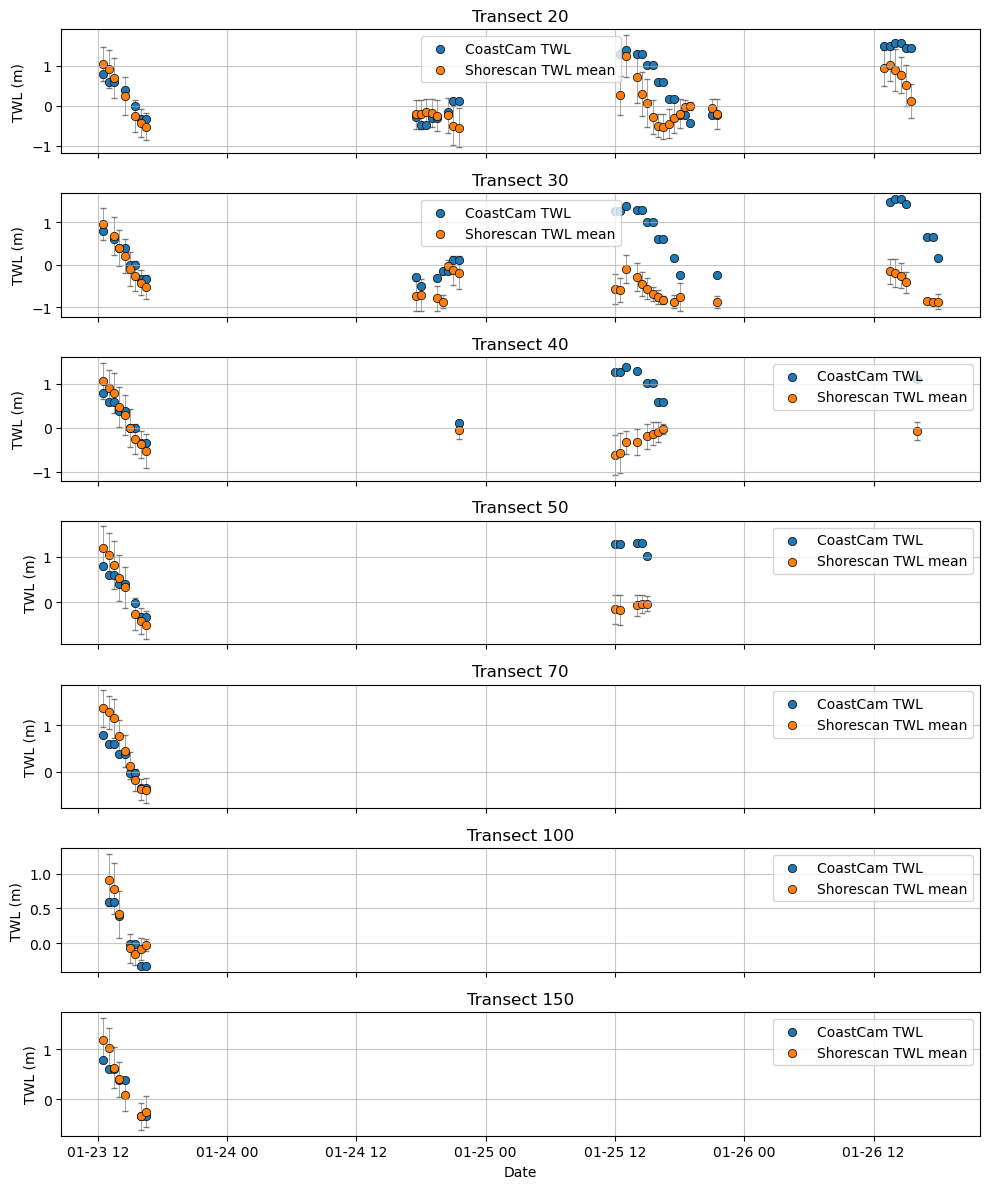

In [63]:

import re
from datetime import datetime, timezone
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from datetime import datetime, timezone

print(len(transects))
fig, axes = plt.subplots(
    len(transects),
    1,
    figsize=(10, 12),
    sharex=True
)

dfAll = pd.DataFrame()
# Handle case where there is only one transect
if len(transects) == 1:
    axes = [axes]

for ax, transect in zip(axes, transects):

    # Convert this transect's records to a dataframe
    df = pd.DataFrame(records[transect])
    dfAll = pd.concat([dfAll,df],axis=0)
    # Extract variables
    x_values = pd.to_datetime(df["timestamp"], unit="s", utc=True)
    y_values = df["ss_twl_mean"]


    ax.scatter(
    x_values,
    df["cc_twl"],
    label="CoastCam TWL",
    edgecolor='k',
    linewidth=0.5,
    )

    ax.scatter(
    x_values,
    df["ss_twl_mean"],
    label="Shorescan TWL mean",
    edgecolor='k',
    linewidth=0.5,
    )

    ax.errorbar(
        x_values,
        df["ss_twl_mean"],
        yerr=df["ss_twl_std"],
        fmt='none',
        ecolor="black",
        alpha=0.5,
        capsize=2,
        zorder=0,
        linewidth=0.5,
        
    )

    ax.set_title(f"Transect {transect}")
    ax.set_ylabel("TWL (m)")
    ax.grid(alpha=0.7)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

dfAll.to_csv("Shorescan_TWLviewer_AllTransects_01232025-01262025subset2.csv")

Plotting TWL comparison as a function of slope

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.metrics import r2_score
import numpy as np

# Create figure
plt.figure(figsize=(12, 9))

# Color map based on number of transects
transects = sorted(records.keys())
cmap = cm.get_cmap('viridis', len(transects))
first_date = df["timestamp"].min()
first_dt = np.datetime64(
        datetime.fromtimestamp(first_date, tz=timezone.utc))
first_dt = pd.to_datetime(first_dt)


last_date = df["timestamp"].max()
last_dt = np.datetime64(
        datetime.fromtimestamp(last_date, tz=timezone.utc))
last_dt = pd.to_datetime(last_dt)

all_x = []
all_y = []
all_slopes = []

for transect in transects:
    df = pd.DataFrame(records[transect])
    all_slopes.extend(df["beta06"])

all_slopes = np.asarray(all_slopes)

slope_min = np.nanmin(all_slopes)
slope_max = np.nanmax(all_slopes)

for i, transect in enumerate(transects):

    df = pd.DataFrame(records[transect])
    slope = np.array(df["beta06"])
    cc_twl = np.array(df["cc_twl"])
    ss_twl_mean = np.array(df["ss_twl_mean"])

  
    # Store for overall limits
    all_x.append(np.asarray(cc_twl, dtype=float))
    all_y.append(np.asarray(ss_twl_mean, dtype=float))
   
    sizes = 25 + 175 * (
        (slope - slope_min) /
        (slope_max - slope_min)
    )
 

    # Statistics
    r2 = r2_score(cc_twl, ss_twl_mean)
    bias = np.mean(ss_twl_mean - cc_twl)
    rmse = np.sqrt(np.mean((ss_twl_mean - cc_twl)**2))
    # Plot data points
    plt.errorbar(
        cc_twl,
        ss_twl_mean,
        yerr=df["ss_twl_std"],
        fmt='none',
        ecolor="black",
        alpha=0.25,
        capsize=2,
        zorder=1,
        linewidth=0.5
    )

    plt.scatter(
        cc_twl,
        ss_twl_mean,
        s=sizes,
        alpha=1,
        color=cmap(i),
        edgecolor='k',
        linewidth=0.5,
        label=f'Transect {transect} (n={len(df)}, $R^2$={r2:.2f})'
    )


# 1:1 line
all_x = np.concatenate([np.asarray(x, dtype=float) for x in all_x])
all_y = np.concatenate([np.asarray(y, dtype=float) for y in all_y])




mn = np.nanmin(np.asarray(all_x, dtype=float))
mx = np.nanmax(np.asarray(all_y, dtype=float))

all_timestamps = [
    r["timestamp"]
    for transect_records in records.values()
    for r in transect_records
]

dtmin = datetime.fromtimestamp(
    min(all_timestamps),
    tz=timezone.utc
)

dtmax = datetime.fromtimestamp(
    max(all_timestamps),
    tz=timezone.utc
)

plt.plot(
    [mn, mx],
    [mn, mx],
    'k--',
    lw=1.5,
    label='1:1'
)

coefficients = np.polyfit(all_x, all_y, deg=1)
slope, intercept = coefficients
regression_line = slope * all_x + intercept

plt.plot(all_x, regression_line, 
         color='red', 
         label=f'Regression Line: y={slope:.2f}x+{intercept:.2f}')

plt.xlabel('TWL Viewer TWL (m)')
plt.ylabel('Shorescan TWL mean (m)')



plt.title(f'TWL Comparison by Transect \n {dtmin:%Y-%m-%d %H:%M:%S} - {dtmax:%Y-%m-%d %H:%M:%S}')

plt.axis('equal')
plt.xlim(mn, mx)
plt.ylim(mn, mx)

plt.grid(alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=9
)
slope_values = [
    np.nanmin(all_slopes),
    np.percentile(all_slopes,75),
    np.nanmax(all_slopes)
]

for s in slope_values:
    marker_size = 25 + 175 * (
        (s - slope_min) /
        (slope_max - slope_min)
    )

    plt.scatter(
        [],
        [],
        s=marker_size,
        color='gray',
        edgecolor='k',
        linewidth=0.5,
        label=f'β = {s:.3f}'
    )

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='center left',
    fontsize=9
)
plt.tight_layout()
plt.show()

Plotting runup as a function of slope

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.metrics import r2_score
import numpy as np

# Create figure
plt.figure(figsize=(12, 9))

# Color map based on number of transects
transects = sorted(records.keys())

cmap = cm.get_cmap('turbo', len(transects))
# cmap = cm.get_cmap('viridis', len(transects))
first_date = df["timestamp"].min()
first_dt = np.datetime64(
        datetime.fromtimestamp(first_date, tz=timezone.utc))
first_dt = pd.to_datetime(first_dt)


last_date = df["timestamp"].max()
last_dt = np.datetime64(
        datetime.fromtimestamp(last_date, tz=timezone.utc))
last_dt = pd.to_datetime(last_dt)

all_x = []
all_y = []
all_slopes = []

for transect in transects:
    df = pd.DataFrame(records[transect])
    all_slopes.extend(df["beta06"])

all_slopes = np.asarray(all_slopes)

slope_min = np.nanmin(all_slopes)
slope_max = np.nanmax(all_slopes)

for i, transect in enumerate(transects):

    df = pd.DataFrame(records[transect])
    
    slope = np.array(df["beta06"])
    cc_ru_2pct = np.array(df['cc_ru_2pct'])
    ss_ru_2pct = np.array(df["ss_ru_2pct"])
    # Store for overall limits
    all_x.append(np.asarray(cc_ru_2pct, dtype=float))
    all_y.append(np.asarray(ss_ru_2pct, dtype=float))
    '''
    slope = np.array(df["beta06"])
    cc_twl = np.array(df["cc_twl"])
    ss_twl_mean = np.array(df["ss_twl_mean"])
    # Store for overall limits
    all_x.append(np.asarray(cc_twl, dtype=float))
    all_y.append(np.asarray(ss_twl_mean, dtype=float))
    '''
   
    sizes = 25 + 175 * (
        (slope - slope_min) /
        (slope_max - slope_min)
    )
    # Statistics
    r2 = r2_score(cc_ru_2pct, ss_ru_2pct)
    bias = np.mean(ss_ru_2pct - cc_ru_2pct)
    rmse = np.sqrt(np.mean((ss_ru_2pct - cc_ru_2pct)**2))

    plt.errorbar(
        cc_ru_2pct,
        ss_ru_2pct,
        yerr=df["ss_zrunup_std"],
        fmt='none',
        ecolor="black",
        alpha=0.25,
        capsize=2,
        zorder=1,
        linewidth=0.5
    )
    
    plt.scatter(
        cc_ru_2pct,
        ss_ru_2pct,
        s=sizes,
        alpha=1,
        color=cmap(i),
        edgecolor='k',
        linewidth=0.5,
        label=f'Transect {transect} (n={len(df)}, $R^2$={r2:.2f})')
    
    

    '''
    # Statistics
    r2 = r2_score(cc_twl, ss_twl_mean)
    bias = np.mean(ss_twl_mean - cc_twl)
    rmse = np.sqrt(np.mean((ss_twl_mean - cc_twl)**2))
    plt.errorbar(
        cc_twl,
        ss_twl_mean,
        yerr=df["ss_twl_std"],
        fmt='none',
        ecolor="black",
        alpha=0.25,
        capsize=2,
        zorder=1,
        linewidth=0.5
    )
    
    plt.scatter(
        cc_twl,
        ss_twl_mean,
        s=sizes,
        alpha=1,
        color=cmap(i),
        edgecolor='k',
        linewidth=0.5,
        label=f'Transect {transect} (n={len(df)}, $R^2$={r2:.2f})'
    )
'''

# 1:1 line
all_x = np.concatenate([np.asarray(x, dtype=float) for x in all_x])
all_y = np.concatenate([np.asarray(y, dtype=float) for y in all_y])

coefficients = np.polyfit(all_x, all_y, deg=1)
slope, intercept = coefficients
regression_line = slope * all_x + intercept

plt.plot(all_x, regression_line, 
         color='red', 
         label=f'Regression Line: y={slope:.2f}x+{intercept:.2f}')

mn = np.nanmin(np.asarray(all_x, dtype=float))
mx = np.nanmax(np.asarray(all_y, dtype=float))

plt.plot(
    [mn, mx],
    [mn, mx],
    'k--',
    lw=1.5,
    label='1:1'
)


plt.xlabel('TWL Viewer 2% Exceedance Runup')
plt.ylabel('Shorescan 2% Exceedance Runup')

all_timestamps = [
    r["timestamp"]
    for transect_records in records.values()
    for r in transect_records
]

dtmin = datetime.fromtimestamp(
    min(all_timestamps),
    tz=timezone.utc
)

dtmax = datetime.fromtimestamp(
    max(all_timestamps),
    tz=timezone.utc
)

plt.title(f'Runup Comparison by Transect \n {dtmin:%Y-%m-%d %H:%M:%S} - {dtmax:%Y-%m-%d %H:%M:%S}')

plt.axis('equal')
plt.xlim(mn, mx)
plt.ylim(mn, mx)

plt.grid(alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize=9
)
slope_values = [
    np.nanmin(all_slopes),
    np.percentile(all_slopes,75),
    np.nanmax(all_slopes)
]

for s in slope_values:
    marker_size = 25 + 175 * (
        (s - slope_min) /
        (slope_max - slope_min)
    )

    plt.scatter(
        [],
        [],
        s=marker_size,
        color='gray',
        edgecolor='k',
        linewidth=0.5,
        label=f'β = {s:.3f}'
    )

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc='center left',
    fontsize=9
)
plt.tight_layout()
plt.show()